# 08. Phân tích tuổi và khoảng cách chuyến bay

Xem tuổi và khoảng cách bay khác nhau thế nào giữa hai trạng thái hài lòng, sau đó chia nhóm để so sánh tỷ lệ.

## Đọc dữ liệu

Dùng dữ liệu sạch với hai cột nhãn `satisfaction` và `satisfaction_binary`.

In [1]:
%matplotlib inline
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv("data/airline_clean.csv")

## Tuổi theo mức độ hài lòng

Tính số người, tuổi trung bình, trung vị và độ lệch chuẩn ở mỗi trạng thái.

In [2]:
age_summary = df.groupby("satisfaction")["Age"].agg(
    ["count", "mean", "median", "std"]
)
print(age_summary.round(2))

                         count   mean  median    std
satisfaction                                        
neutral or dissatisfied  73452  37.65    37.0  16.47
satisfied                56428  41.74    43.0  12.80


## Tỷ lệ hài lòng theo nhóm tuổi

Chia tuổi bằng `pd.cut()`. Các khoảng là [0,18], (18,30], (30,45], (45,60], (60,100], tức lấy cả đầu bên phải. Với tuổi nguyên, khoảng (18,30] được ghi là 19 đến 30 tuổi.

`observed=True` chỉ giữ nhóm có dữ liệu. Lấy trung bình nhãn 0/1 rồi nhân 100 để tính tỷ lệ hài lòng.

age_group
<=18     17.62
19-30    35.64
31-45    48.81
46-60    57.43
>60      20.82
Name: satisfaction_binary, dtype: float64


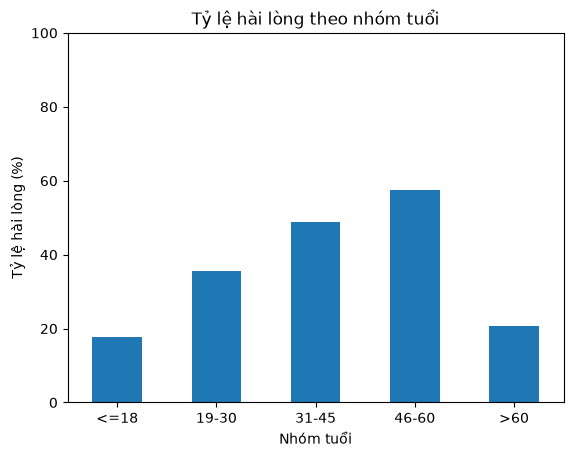

In [3]:
df["age_group"] = pd.cut(
    df["Age"],
    bins=[0, 18, 30, 45, 60, 100],
    labels=["<=18", "19-30", "31-45", "46-60", ">60"],
    include_lowest=True
)

age_rate = df.groupby("age_group", observed=True)["satisfaction_binary"].mean() * 100

print(age_rate.round(2))

age_rate.plot(kind="bar")
plt.title("Tỷ lệ hài lòng theo nhóm tuổi")
plt.ylabel("Tỷ lệ hài lòng (%)")
plt.xlabel("Nhóm tuổi")
plt.xticks(rotation=0)
plt.ylim(0, 100)
plt.show()

## Khoảng cách bay theo mức độ hài lòng

So sánh số người, khoảng cách trung bình, trung vị và độ lệch chuẩn giữa hai trạng thái.

In [4]:
distance_summary = df.groupby("satisfaction")["Flight Distance"].agg(["count", "mean", "median", "std"])

print(distance_summary.round(2))

                         count     mean  median      std
satisfaction                                            
neutral or dissatisfied  73452   929.72   674.0   791.29
satisfied                56428  1529.54  1249.0  1127.60


## Tỷ lệ hài lòng theo nhóm khoảng cách

Dùng các khoảng [0,500], (500,1000], (1000,2000], (2000,5000] như script của nhóm. Nhãn >2000 ở đây chỉ tính đến 5000.

Tuổi và khoảng cách trong dữ liệu hiện tại đều nằm trong các biên đã chọn. Nếu có giá trị ngoài biên, `pd.cut()` sẽ gán giá trị thiếu và người đó không được tính vào tỷ lệ nhóm.

distance_group
<=500        33.56
501-1000     32.49
1001-2000    46.09
>2000        69.71
Name: satisfaction_binary, dtype: float64


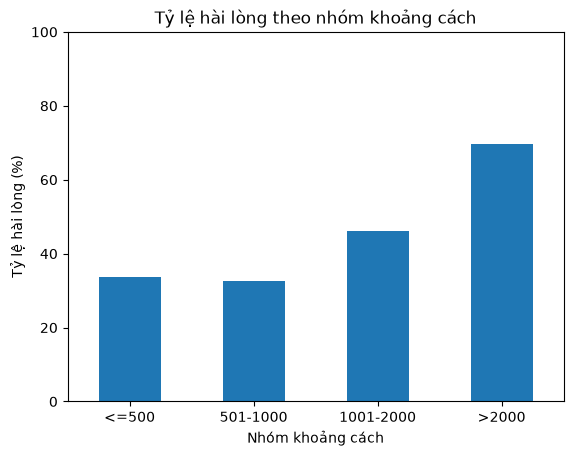

In [5]:
df["distance_group"] = pd.cut(
    df["Flight Distance"],
    bins=[0, 500, 1000, 2000, 5000],
    labels=["<=500", "501-1000", "1001-2000", ">2000"],
    include_lowest=True
)

distance_rate = df.groupby("distance_group", observed=True)["satisfaction_binary"].mean() * 100

print(distance_rate.round(2))

distance_rate.plot(kind="bar")
plt.title("Tỷ lệ hài lòng theo nhóm khoảng cách")
plt.ylabel("Tỷ lệ hài lòng (%)")
plt.xlabel("Nhóm khoảng cách")
plt.xticks(rotation=0)
plt.ylim(0, 100)
plt.show()

## Nhận xét

Trong các nhóm tuổi, nhóm 46 đến 60 tuổi có tỷ lệ hài lòng cao nhất (57,43%), còn nhóm từ 18 tuổi trở xuống thấp nhất (17,62%).

Nhóm bay trên 2000 đến 5000 có tỷ lệ hài lòng 69,71%. Tuy vậy, tỷ lệ không tăng đều theo khoảng cách: nhóm từ 500 trở xuống đạt 33,56%, cao hơn một chút so với nhóm 501 đến 1000 (32,49%). Cần cập nhật các con số này nếu thay dữ liệu.

Phân tích này mô tả bộ dữ liệu Airline Passenger Satisfaction, chưa đại diện cho mọi hành khách và chưa chứng minh tuổi hay khoảng cách bay gây ra sự khác biệt về hài lòng. Phần kiểm định nằm ở notebook 09.